# <span style="color: #a855f7">PyTorch basics</span>

<span style="color: #a855f7">тензори, autograd і лінійний нейрон у PyTorch, ручне оновлення параметрів та SGD, порівняння MSE за 20 епох, дані синтетичні, умовний показник ризику не є ймовірністю чи реальною страховою оцінкою</span>

In [1]:
from copy import deepcopy
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import HTML, display
from matplotlib.ticker import MaxNLocator
from torch import nn

RANDOM_STATE = 42
EPOCHS = 20
LEARNING_RATE = 0.01
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]
OUTPUT_PATH = Path("loss_healthrisk.png")


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<p style="color: #a855f7; margin: 12px 0 6px">{escape(str(value))}</p>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})

## <span style="color: #a855f7">Tensors and autograd</span>

<span style="color: #a855f7">1D - вік чотирьох клієнтів, 2D - рядки клієнтів і стовпці age, weight, height, 3D - два батчі по два клієнти, torch.manual_seed(42) фіксує генератор, умовний risk = age / 100 + BMI / 50 використовує додавання і поелементне множення, leaf-тензор має grad_fn=None, результат обчислень має grad_fn</span>

In [2]:
torch.manual_seed(RANDOM_STATE)
ages = torch.tensor([25.0, 35.0, 45.0, 55.0], requires_grad=True)
weights = torch.tensor([60.0, 75.0, 90.0, 105.0])
heights = torch.tensor([1.65, 1.70, 1.75, 1.80])
clients = torch.stack((ages.detach(), weights, heights), dim=1)
client_batches = clients.reshape(2, 2, 3)
bmi = weights / (heights * heights)
risk_components = ages * 0.01 + bmi * 0.02
risk_mean = risk_components.mean()
risk_mean.backward()

colorize(pd.DataFrame({
    "tensor": ["ages", "clients", "client_batches", "risk", "mean risk"],
    "shape": [str(tuple(t.shape)) for t in (ages, clients, client_batches, risk_components, risk_mean)],
    "requires_grad": [t.requires_grad for t in (ages, clients, client_batches, risk_components, risk_mean)],
    "grad_fn": [type(t.grad_fn).__name__ if t.grad_fn is not None else "None"
                for t in (ages, clients, client_batches, risk_components, risk_mean)],
}), index=False)
colorize("1D tensor: client ages")
colorize(pd.DataFrame({"age (years)": ages.detach().tolist()}).rename_axis("client"))
colorize("2D tensor: client measurements")
colorize(pd.DataFrame(clients.tolist(), columns=["age (years)", "weight (kg)", "height (m)"]).rename_axis("client"))
colorize("3D tensor: batches shown as rows indexed by batch and client")
colorize(pd.DataFrame(
    client_batches.reshape(-1, 3).tolist(),
    index=pd.MultiIndex.from_product([range(2), range(2)], names=["batch", "client in batch"]),
    columns=["age (years)", "weight (kg)", "height (m)"],
))
colorize("Conditional risk and gradient of mean risk")
colorize(pd.DataFrame({
    "age (years)": ages.detach().tolist(),
    "BMI": bmi.tolist(),
    "risk": risk_components.detach().tolist(),
    "mean risk gradient": ages.grad.tolist() if ages.grad is not None else None,
}).round(4), index=False)

tensor,shape,requires_grad,grad_fn
ages,"(4,)",True,None
clients,"(4, 3)",False,None
client_batches,"(2, 2, 3)",False,None
risk,"(4,)",True,AddBackward0
mean risk,(),True,MeanBackward0


,age (years)
client,
0,25.0
1,35.0
2,45.0
3,55.0


,age (years),weight (kg),height (m)
client,,,
0,25.0,60.0,1.65
1,35.0,75.0,1.70
2,45.0,90.0,1.75
3,55.0,105.0,1.80


age (years),BMI,risk,mean risk gradient
25.0,22.0386,0.6908,0.0025
35.0,25.9516,0.8690,0.0025
45.0,29.3878,1.0378,0.0025
55.0,32.4074,1.1981,0.0025


## <span style="color: #a855f7">Synthetic data and initial model</span>

<span style="color: #a855f7">100 зразків і одна ознака через torch.randn(100, 1), X моделює BMI у стандартизованій шкалі, тому може бути від'ємним і не є сирим BMI, y = 2.5 × X + 1 + шум зі std 0.1, nn.Linear(1, 1) передбачає безперервне значення, MSE порівнює тензори однакової форми (100, 1)</span>

In [3]:
torch.manual_seed(RANDOM_STATE)
X = torch.randn(100, 1)
y = 2.5 * X + 1.0 + 0.1 * torch.randn(100, 1)
if X.shape != y.shape or not torch.isfinite(X).all() or not torch.isfinite(y).all():
    raise ValueError("Features and targets must have matching shapes and finite values")
criterion = nn.MSELoss()
initial_model = nn.Linear(1, 1)


def measure_model(model, inputs, targets):
    with torch.no_grad():
        mse = torch.mean((model(inputs) - targets) ** 2).item()
    return {"weight": model.weight.item(), "bias": model.bias.item(), "MSE": mse}


initial_metrics = measure_model(initial_model, X, y)
colorize(f"Features shape: {tuple(X.shape)} | targets shape: {tuple(y.shape)}")
colorize(pd.DataFrame({"BMI feature": X.flatten().numpy(), "risk target": y.flatten().numpy()}).head().round(4))
colorize(pd.DataFrame([{"stage": "initial", **initial_metrics}]).round(6), index=False)

,BMI feature,risk target
0,1.9269,5.8899
1,1.4873,4.7273
2,0.9007,3.2129
3,-2.1055,-4.2110
4,0.6784,2.7992


stage,weight,bias,MSE
initial,0.480106,0.841504,4.02223


## <span style="color: #a855f7">Manual parameter updates</span>

<span style="color: #a855f7">20 епох, model.zero_grad очищує попередні градієнти, backward обчислює нові, оновлення parameter -= lr × grad виконується в torch.no_grad без .data, MSE записується після оновлення, тому фінальний loss відповідає фінальним weight і bias, епоха 0 позначає стан до навчання</span>

In [4]:
manual_model = deepcopy(initial_model)
manual_model.train()
manual_history = []
for epoch in range(1, EPOCHS + 1):
    manual_model.zero_grad(set_to_none=True)
    loss = criterion(manual_model(X), y)
    loss.backward()
    with torch.no_grad():
        for parameter in manual_model.parameters():
            if parameter.grad is None:
                raise RuntimeError("A trainable parameter has no gradient")
            parameter.add_(parameter.grad, alpha=-LEARNING_RATE)
    manual_history.append({"epoch": epoch, **measure_model(manual_model, X, y)})
manual_results = pd.DataFrame(manual_history)
colorize(pd.DataFrame([
    {"stage": "initial", **initial_metrics},
    {"stage": "manual after 20 epochs", **measure_model(manual_model, X, y)},
]).round(6), index=False)

stage,weight,bias,MSE
initial,0.480106,0.841504,4.022230
manual after 20 epochs,1.135748,0.928473,1.828153


## <span style="color: #a855f7">SGD training</span>

<span style="color: #a855f7">torch.optim.SGD(lr=0.01), 20 епох з тими самими даними й копією початкової моделі, optimizer.zero_grad → forward → MSE → backward → optimizer.step, таблиця містить loss після кожного оновлення, один крок використовує всі 100 зразків, тому це full-batch навчання через оптимізатор SGD</span>

In [5]:
sgd_model = deepcopy(initial_model)
sgd_model.train()
optimizer = torch.optim.SGD(sgd_model.parameters(), lr=LEARNING_RATE)
sgd_history = []
for epoch in range(1, EPOCHS + 1):
    optimizer.zero_grad(set_to_none=True)
    loss = criterion(sgd_model(X), y)
    loss.backward()
    optimizer.step()
    sgd_history.append({"epoch": epoch, **measure_model(sgd_model, X, y)})
sgd_results = pd.DataFrame(sgd_history)
colorize(sgd_results[["epoch", "MSE"]].rename(columns={"MSE": "Loss (SGD)"}).round(6), index=False)
colorize(pd.DataFrame([
    {"stage": "initial", **initial_metrics},
    {"stage": "SGD after 20 epochs", **measure_model(sgd_model, X, y)},
]).round(6), index=False)

epoch,Loss (SGD)
1,3.866350
2,3.716547
3,3.572582
4,3.434228
5,3.301264
6,3.173481
7,3.050674
8,2.932651
9,2.819223
10,2.710211


stage,weight,bias,MSE
initial,0.480106,0.841504,4.022230
SGD after 20 epochs,1.135748,0.928473,1.828153


## <span style="color: #a855f7">Loss curves and training results</span>

<span style="color: #a855f7">вісь X - епоха, вісь Y - MSE, обидві криві стартують з епохи 0, звичайний SGD без momentum і ручне оновлення за однакового lr виконують той самий крок, тому криві накладаються, SGD автоматизує оновлення, але сам по собі не гарантує швидшої збіжності, файл графіка зберігається поруч із Notebook</span>

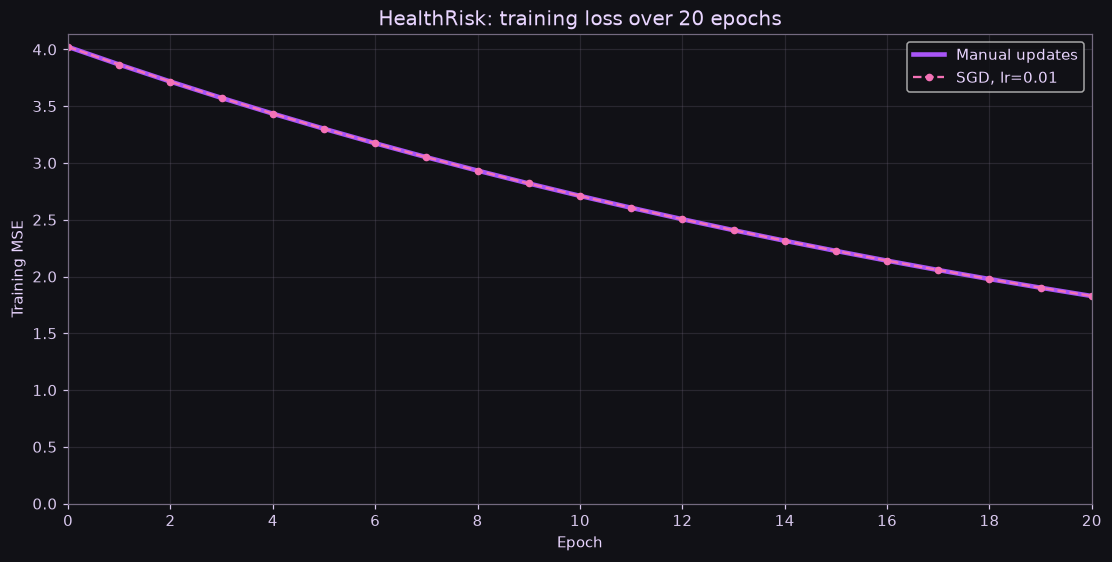

best recorded epoch,weight,bias,MSE
20,1.135748,0.928473,1.828153


In [6]:
epochs = [0, *sgd_results["epoch"].tolist()]
manual_losses = [initial_metrics["MSE"], *manual_results["MSE"].tolist()]
sgd_losses = [initial_metrics["MSE"], *sgd_results["MSE"].tolist()]
fig, ax = plt.subplots(layout="constrained")
ax.plot(epochs, manual_losses, color=COLORS[0], linewidth=3, label="Manual updates")
ax.plot(epochs, sgd_losses, color=COLORS[1], linestyle="--", marker="o", markersize=4, label="SGD, lr=0.01")
ax.set(title="HealthRisk: training loss over 20 epochs", xlabel="Epoch", ylabel="Training MSE")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(0, EPOCHS)
ax.set_ylim(bottom=0)
ax.grid(True)
ax.set_axisbelow(True)
ax.legend()
fig.savefig(OUTPUT_PATH, dpi=160, facecolor=fig.get_facecolor())
plt.show()

best_epoch = sgd_results.loc[sgd_results["MSE"].idxmin()]
loss_reduction = (1 - sgd_losses[-1] / sgd_losses[0]) * 100
weight_min = min(initial_metrics["weight"], float(sgd_results["weight"].min()))
weight_max = max(initial_metrics["weight"], float(sgd_results["weight"].max()))
colorize(pd.DataFrame([{
    "best recorded epoch": int(best_epoch["epoch"]),
    "weight": best_epoch["weight"],
    "bias": best_epoch["bias"],
    "MSE": best_epoch["MSE"],
}]).round(6), index=False)
colorize(f"MSE reduction after {EPOCHS} epochs: {loss_reduction:.2f}%")
colorize(f"Explored weight range, including initialization: [{weight_min:.6f}, {weight_max:.6f}]")
colorize(f"Maximum manual/SGD loss difference: {max(abs(a - b) for a, b in zip(manual_losses, sgd_losses, strict=True)):.8f}")
colorize(f"Saved plot: {OUTPUT_PATH.name}")

<span style="color: #a855f7">зменшення MSE у відсотках показане під графіком, найменший записаний loss і відповідні weight та bias - в підсумковій таблиці, explored weight range показує лише перевірений діапазон коефіцієнта w, це не вага клієнта в кг, за 20 епох не можна встановити весь діапазон глобально оптимальних ваг, мінімізується помилка передбачення ризику, а не сам ризик клієнта, наведення суто навчальне</span>